In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

#ne pas

# 1. Chargement et Split

## 1.1 Chargement

### 1.1.1 Regression 

In [2]:
df = pd.read_parquet('../data/processed/2026-10-12_132605/59.parquet')
df.head()

,configuration_installation_chauffage_n1,conso_chauffage_installation_chauffage_n1,type_generateur_n1_ecs_n1,score_ban,surface_habitable_immeuble,conso_auxiliaires_ep,deperditions_murs,cout_eclairage,conso_auxiliaires_ef,statut_geocodage,...,provenance_id_rnb,id_rnb,nombre_niveau_immeuble,appartement_non_visite,qualite_isolation_plancher_haut_comble_amenage,surface_ventilee,type_ventilation,origine,latitude,longitude
0,Installation de chauffage simple,1007.6,Réseau de chaleur isolé,0.74,6906.0,301.6,8.8,6.4,158.7,adresse géocodée ban à l'adresse,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,dpe_existants,50.629216,3.005483
1,Installation de chauffage simple,3556.9,Chaudière gaz à condensation après 2015,0.59,NaN,599.6,8.5,37.8,315.6,adresse géocodée ban à l'adresse,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,dpe_existants,50.371726,3.194996
2,Installation de chauffage simple,7042.0,Ballon électrique à accumulation vertical Caté...,0.65,NaN,0.0,33.4,29.7,0.0,adresse géocodée ban à l'adresse,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,dpe_existants,50.364151,3.533716
3,Installation de chauffage simple,22052.5,Chaudière gaz à condensation 1986-2000,0.68,NaN,579.4,111.4,62.3,305.0,adresse géocodée ban à l'adresse,...,Logiciel,MV6BVK19M4BV,NaN,NaN,NaN,NaN,NaN,dpe_existants,50.26472,3.957959
4,Installation de chauffage simple,5982.0,Chaudière gaz à condensation après 2015,0.53,NaN,1243.3,23.3,45.9,654.3,adresse géocodée ban à l'adresse,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,dpe_existants,50.039473,3.29219


In [3]:
# variables calculées à partir de la conso (sorties du calcul DPE) -> fuite de données pour les 2 cibles
# conso_* : consommations, cout_* : coûts (= conso x prix), emission_ges_* : émissions (= conso x facteur),
# besoin_* : besoins énergétiques (conso = besoin / rendement), etiquette_* : étiquettes DPE et GES
fuite_list = [col for col in df.columns if col.startswith(('conso_', 'cout_', 'emission_ges', 'besoin_', 'etiquette_'))]
print(len(fuite_list))
fuite_list

54


['conso_chauffage_installation_chauffage_n1',
 'conso_auxiliaires_ep',
 'cout_eclairage',
 'conso_auxiliaires_ef',
 'cout_chauffage',
 'conso_5_usages_par_m2_ep',
 'conso_ecs_ef_energie_n1',
 'conso_ecs_ef_energie_n2',
 'emission_ges_chauffage',
 'conso_5_usages_par_m2_ef',
 'cout_ecs_energie_n2',
 'conso_chauffage_ef_energie_n1',
 'conso_chauffage_ef_energie_n2',
 'cout_total_5_usages_energie_n2',
 'cout_total_5_usages_energie_n1',
 'cout_ecs_energie_n1',
 'conso_chauffage_generateur_n1_installation_n1',
 'emission_ges_eclairage',
 'emission_ges_ecs',
 'conso_5_usages_ef_energie_n2',
 'conso_5_usages_ef',
 'conso_5_usages_ef_energie_n1',
 'conso_5_usages_ep',
 'besoin_ecs',
 'cout_ecs',
 'emission_ges_5_usages_energie_n1',
 'emission_ges_5_usages_energie_n2',
 'emission_ges_5_usages_par_m2',
 'cout_auxiliaires',
 'besoin_chauffage',
 'emission_ges_refroidissement',
 'conso_chauffage_ef',
 'conso_ecs_ep',
 'conso_ecs_ef',
 'emission_ges_5_usages',
 'etiquette_ges',
 'conso_ef_installat

In [4]:
conso_list = [col for col in df.columns if col.startswith('conso')]

On a 32 variables de conso, on va juste garder `conso_5_usages_par_m2_ef` et retirer les autres pour éviter la fuites de données 

In [5]:
y_conso = df["conso_5_usages_par_m2_ef"]
X_conso = df.drop(columns=conso_list)
y_conso

0         264.0
1          90.0
2         122.0
3         257.0
4         120.0
          ...  
138802     36.0
138803     41.9
138804     56.7
138805     84.6
138806     60.0
Name: conso_5_usages_par_m2_ef, Length: 138807, dtype: float64

### 1.1.2 Classification

In [6]:
dpe_list = [col for col in df.columns if col.endswith('dpe')]

In [7]:
dpe_list

['date_etablissement_dpe',
 'date_reception_dpe',
 'modele_dpe',
 'date_fin_validite_dpe',
 'version_dpe',
 'date_derniere_modification_dpe',
 'etiquette_dpe',
 'methode_application_dpe',
 'numero_dpe']

In [8]:
df[["etiquette_dpe","numero_dpe"]].head(10)

,etiquette_dpe,numero_dpe
0,C,2659E0039476U
1,C,2659E0007955L
2,D,2659E0077741N
3,E,2659E0079133B
4,C,2659E0000267T
5,C,2659E0012708G
6,C,2659E0044677V
7,E,2659E0023285B
8,E,2659E0060211H
9,E,2659E0047310C


In [9]:
y_dpe = df["etiquette_dpe"]
X_dpe = df.drop(columns="etiquette_dpe")
y_dpe

0         C
1         C
2         D
3         E
4         C
         ..
138802    B
138803    B
138804    C
138805    C
138806    C
Name: etiquette_dpe, Length: 138807, dtype: string

### 1.1.3 Variables supprimées

On garde uniquement les caractéristiques physiques du logement et de ses équipements (surfaces, isolation, déperditions, chauffage, ECS, ventilation...). Les mêmes colonnes sont retirées pour les 2 cibles :

- **Fuite de données** (`fuite_list`, 54 colonnes) : `conso_*`, `cout_*`, `emission_ges_*`, `besoin_*` et `etiquette_*` sont des sorties du calcul DPE. L'étiquette est calculée à partir de la conso et des émissions, et les coûts / émissions sont la conso multipliée par un prix ou un facteur. Les garder revient à donner la réponse au modèle.
- **Identifiants** (`id_list`) : `numero_dpe`, `_id`, `_i`, `_rand`, `identifiant_ban`, `id_rnb`. Une valeur unique (ou presque) par ligne, aucun pouvoir prédictif, le modèle ne peut que les apprendre par cœur.
- **Adresses et localisation** (`localisation_list`) : adresses en texte libre (jusqu'à 92 000 modalités, qui font exploser le OneHotEncoder), codes postaux, communes, coordonnées, et la qualité du géocodage (`score_ban`, `statut_geocodage`). On veut prédire à partir du logement, pas de son emplacement. `zone_climatique` et `classe_altitude` sont gardées : ce sont des entrées officielles du calcul DPE avec peu de modalités.
- **Descriptions** (`description_list`) : `description_*` sont du texte libre (jusqu'à 5 400 modalités) qui répète l'information déjà présente dans les colonnes `type_*`.
- **Informations sur le diagnostic** (`info_dpe_list`) : `modele_dpe`, `version_dpe`, `methode_application_dpe`, `origine`, `provenance_id_rnb`, `appartement_non_visite`. Elles décrivent comment le DPE a été réalisé, pas le logement. Le caractère neuf / existant reste porté par `annee_construction` et `periode_construction`, et maison / appartement par `type_batiment`.
- **Dates du diagnostic** (`date_list`) : `date_etablissement_dpe`, `date_reception_dpe`, `date_visite_diagnostiqueur` (quasi identiques entre elles), `date_fin_validite_dpe` (= établissement + 10 ans) et `date_derniere_modification_dpe` (date technique de la base). Tous les DPE sont postérieurs à la réforme de juillet 2021, donc la date n'apporte rien sur le logement, et en texte elles seraient encodées en ~1 500 colonnes chacune. L'âge du logement reste porté par `annee_construction` et `periode_construction`.

In [10]:
# on retire les identifiants et les variables qui fuient (cf. fuite_list) avant le split
id_list = ['numero_dpe', '_id', '_i', '_rand', 'identifiant_ban', 'id_rnb']
# adresses et localisation : texte libre ou codes géographiques, pas des caractéristiques du logement
localisation_list = ['adresse_ban', 'adresse_brut', 'adresse_complete_brut', 'complement_adresse_batiment',
                     'complement_adresse_logement', 'nom_rue_ban', 'numero_voie_ban',
                     'code_postal_ban', 'code_postal_brut', 'code_insee_ban', 'nom_commune_ban', 'nom_commune_brut',
                     'code_departement_ban', 'code_region_ban', 'coordonnee_cartographique_x_ban',
                     'coordonnee_cartographique_y_ban', 'latitude', 'longitude', 'score_ban', 'statut_geocodage']
# descriptions en texte libre, redondantes avec les colonnes type_*
description_list = [col for col in df.columns if col.startswith('description_')]
# informations sur le diagnostic lui-même, pas sur le logement
info_dpe_list = ['modele_dpe', 'version_dpe', 'methode_application_dpe', 'origine', 'provenance_id_rnb',
                 'appartement_non_visite']
# dates du diagnostic (l'âge du logement reste dans annee_construction / periode_construction)
date_list = ['date_etablissement_dpe', 'date_reception_dpe', 'date_fin_validite_dpe',
             'date_visite_diagnostiqueur', 'date_derniere_modification_dpe']
drop_list = fuite_list + id_list + localisation_list + description_list + info_dpe_list + date_list
X_dpe = df.drop(columns=drop_list)
X_conso = df.drop(columns=drop_list)
print(f"shape X_dpe: {X_dpe.shape}, X_conso: {X_conso.shape}")

shape X_dpe: (138807, 64), X_conso: (138807, 64)


## 1.2 Split

On prend 70 / 30 pour train / test

In [11]:
X_dpe_train, X_dpe_test, y_dpe_train, y_dpe_test = train_test_split(X_dpe, y_dpe, test_size=0.3, random_state=42)
X_conso_train, X_conso_test, y_conso_train, y_conso_test = train_test_split(X_conso, y_conso, test_size=0.3, random_state=42)

In [12]:
print(f"shape train dpe: {X_dpe_train.shape}, test dpe: {X_dpe_test.shape}")
print(f"shape train conso: {X_conso_train.shape}, test conso: {X_conso_test.shape}")

shape train dpe: (97164, 64), test dpe: (41643, 64)
shape train conso: (97164, 64), test conso: (41643, 64)


In [13]:
print(f"nb de données qualitatives dpe: {X_dpe_train.select_dtypes(include='object').columns.size}")
print(f"nb de données qualitatives conso: {X_conso_train.select_dtypes(include='object').columns.size}")  

print(f"nb de données quantitatives dpe: {X_dpe_train.select_dtypes(include='number').columns.size}")
print(f"nb de données quantitatives conso: {X_conso_train.select_dtypes(include='number').columns.size}")  

nb de données qualitatives dpe: 31
nb de données qualitatives conso: 31
nb de données quantitatives dpe: 33
nb de données quantitatives conso: 33


/tmp/ipykernel_17647/1010822538.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(f"nb de données qualitatives dpe: {X_dpe_train.select_dtypes(include='object').columns.size}")
/tmp/ipykernel_17647/1010822538.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-

In [14]:
quant_cols_dpe = X_dpe.select_dtypes(include='number').columns
quali_cols_dpe = X_dpe.select_dtypes(exclude='number').columns

## 1.3 Imputer

Possibilité : SimpleImputer (+ fréquent / médiane), pas possible les autres imputer pck on a pas que du numérique...

In [15]:
from sklearn.impute import SimpleImputer


In [16]:
quanti_imputer = SimpleImputer(strategy='median')
quali_imputer = SimpleImputer(strategy='most_frequent')

## 1.4 Scaler / Encoder

In [17]:
scaler = StandardScaler()
encoder = OneHotEncoder(handle_unknown='ignore')    

## 1.5 Sélection de variable

en fonction du modèle qu'on choisira, il faudra peut être en rajouter...

In [18]:
from sklearn.feature_selection import VarianceThreshold, SelectKBest

In [19]:
var = VarianceThreshold()
select_k_best = SelectKBest(k=20) #il faudra trouver le bon k pour la sélection des features

```python
# Le nombre de variables k se règle comme un hyperparamètre
param_grid = {"selection__k": [10, 20, 50, "all"]}
search = GridSearchCV(pipe, param_grid, cv=5, scoring="f1")
```

il faudra ajouter ça pour chercher le bon K

## 1.5 Model

### 1.5.1 Classification

Pour l'étiquette DPE, on peut tester: logisticregression, randomforest, linearSVC, 

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report

preprocess_dpe = ColumnTransformer([
    ("quanti", Pipeline([("imputer", quanti_imputer), ("scaler", scaler)]), quant_cols_dpe),
    ("quali", Pipeline([("imputer", quali_imputer), ("encoder", encoder)]), quali_cols_dpe),
])

pipe_dpe = Pipeline([
    ("preprocess", preprocess_dpe),
    ("variance", var),
    ("selection", select_k_best),
    ("model", LogisticRegression(max_iter=1000)),
    ]   
)

param_grid = {"selection__k": [10, 20, 50, "all"]}
search_dpe = GridSearchCV(pipe_dpe, param_grid, cv=2, scoring="f1_macro", n_jobs=-1)
search_dpe.fit(X_dpe_train, y_dpe_train)

print(search_dpe.best_params_)
print(classification_report(y_dpe_test, search_dpe.predict(X_dpe_test)))

{'selection__k': 'all'}
              precision    recall  f1-score   support

           A       0.85      0.87      0.86      2301
           B       0.62      0.31      0.41      2900
           C       0.77      0.82      0.80     14822
           D       0.61      0.69      0.65     11084
           E       0.52      0.54      0.53      6572
           F       0.54      0.30      0.39      2610
           G       0.66      0.55      0.60      1354

    accuracy                           0.67     41643
   macro avg       0.65      0.58      0.61     41643
weighted avg       0.66      0.67      0.66     41643



In [21]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate

# on garde le k trouvé par le GridSearch de la LogisticRegression ci-dessus
best_k = search_dpe.best_params_["selection__k"]

# LinearSVC retiré : moins bon que les 2 autres (f1_macro 0.52) et ~350 s par fit
modeles_dpe = {
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "RandomForest": RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42),
}

resultats_dpe = []
for nom, modele in modeles_dpe.items():
    pipe = Pipeline([
        ("preprocess", preprocess_dpe),
        ("variance", var),
        ("selection", SelectKBest(k=best_k)),
        ("model", modele),
    ])
    cv = cross_validate(pipe, X_dpe_train, y_dpe_train, cv=3, scoring=["f1_macro", "accuracy"])
    resultats_dpe.append({
        "modele": nom,
        "f1_macro": cv["test_f1_macro"].mean(),
        "accuracy": cv["test_accuracy"].mean(),
        "temps_fit (s)": cv["fit_time"].mean(),
    })

pd.DataFrame(resultats_dpe).sort_values("f1_macro", ascending=False).set_index("modele").round(3)

,f1_macro,accuracy,temps_fit (s)
modele,,,
RandomForest,0.728,0.775,53.207
LogisticRegression,0.599,0.667,42.103


In [22]:
# recherche des hyperparamètres du RandomForest (meilleur modèle de la comparaison)
# 8 combinaisons x 2 plis = 16 fits (~45 s chacun)
pipe_rf = Pipeline([
    ("preprocess", preprocess_dpe),
    ("variance", var),
    ("selection", SelectKBest(k=best_k)),
    ("model", RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)),
])

param_grid_rf = {
    "model__max_depth": [None, 20],
    "model__min_samples_leaf": [1, 5],
    "model__class_weight": [None, "balanced"],  # "balanced" pour aider les classes rares (B, F, G)
}
search_rf = GridSearchCV(pipe_rf, param_grid_rf, cv=2, scoring="f1_macro", return_train_score=True)
search_rf.fit(X_dpe_train, y_dpe_train)

print(search_rf.best_params_)
# écart train / CV : un score train proche de 1 est normal pour un RandomForest, ce qui compte c'est le score CV / test
print(f"f1_macro train: {search_rf.cv_results_['mean_train_score'][search_rf.best_index_]:.3f}")
print(f"f1_macro CV: {search_rf.best_score_:.3f}")
print(classification_report(y_dpe_test, search_rf.predict(X_dpe_test)))

{'model__class_weight': 'balanced', 'model__max_depth': None, 'model__min_samples_leaf': 1}
f1_macro train: 0.980
f1_macro CV: 0.735
              precision    recall  f1-score   support

           A       0.95      0.95      0.95      2301
           B       0.77      0.83      0.80      2900
           C       0.92      0.82      0.86     14822
           D       0.72      0.79      0.76     11084
           E       0.65      0.72      0.68      6572
           F       0.61      0.57      0.59      2610
           G       0.77      0.66      0.71      1354

    accuracy                           0.78     41643
   macro avg       0.77      0.76      0.77     41643
weighted avg       0.79      0.78      0.79     41643



In [23]:
# max_depth et min_samples_leaf sont déjà au réglage le plus permissif : on les fixe
# et on cherche sur le nombre d'arbres et le nombre de variables testées à chaque découpage
# 4 combinaisons x 2 plis = 8 fits, plus longs que la grille précédente (plus d'arbres / de variables)
pipe_rf.set_params(**search_rf.best_params_)

param_grid_rf2 = {
    "model__n_estimators": [100, 300],
    "model__max_features": ["sqrt", 0.3],
}
search_rf2 = GridSearchCV(pipe_rf, param_grid_rf2, cv=2, scoring="f1_macro", return_train_score=True)
search_rf2.fit(X_dpe_train, y_dpe_train)

print(search_rf2.best_params_)
print(f"f1_macro train: {search_rf2.cv_results_['mean_train_score'][search_rf2.best_index_]:.3f}")
print(f"f1_macro CV: {search_rf2.best_score_:.3f}")
print(classification_report(y_dpe_test, search_rf2.predict(X_dpe_test)))

pd.DataFrame(search_rf2.cv_results_)[["params", "mean_train_score", "mean_test_score", "mean_fit_time"]].round(3)

{'model__max_features': 0.3, 'model__n_estimators': 300}
f1_macro train: 0.979
f1_macro CV: 0.766
              precision    recall  f1-score   support

           A       0.95      0.95      0.95      2301
           B       0.77      0.84      0.80      2900
           C       0.93      0.85      0.89     14822
           D       0.79      0.82      0.80     11084
           E       0.71      0.76      0.74      6572
           F       0.65      0.67      0.66      2610
           G       0.78      0.72      0.75      1354

    accuracy                           0.82     41643
   macro avg       0.80      0.80      0.80     41643
weighted avg       0.82      0.82      0.82     41643



,params,mean_train_score,mean_test_score,mean_fit_time
0,"{'model__max_features': 'sqrt', 'model__n_esti...",0.980,0.735,32.311
1,"{'model__max_features': 'sqrt', 'model__n_esti...",0.981,0.741,88.326
2,"{'model__max_features': 0.3, 'model__n_estimat...",0.978,0.763,66.204
3,"{'model__max_features': 0.3, 'model__n_estimat...",0.979,0.766,216.957


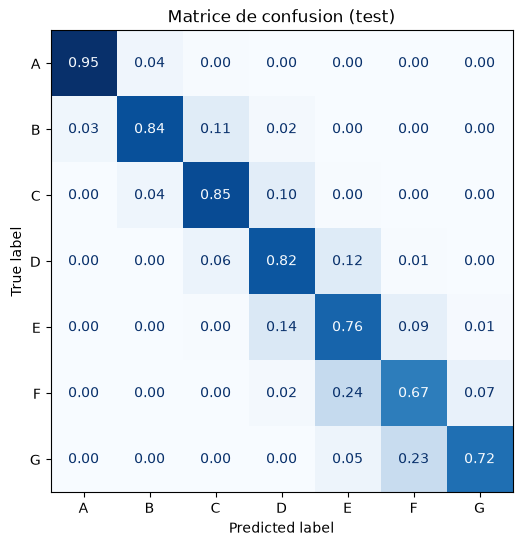

prédictions exactes: 0.817
prédictions à une classe près: 0.989


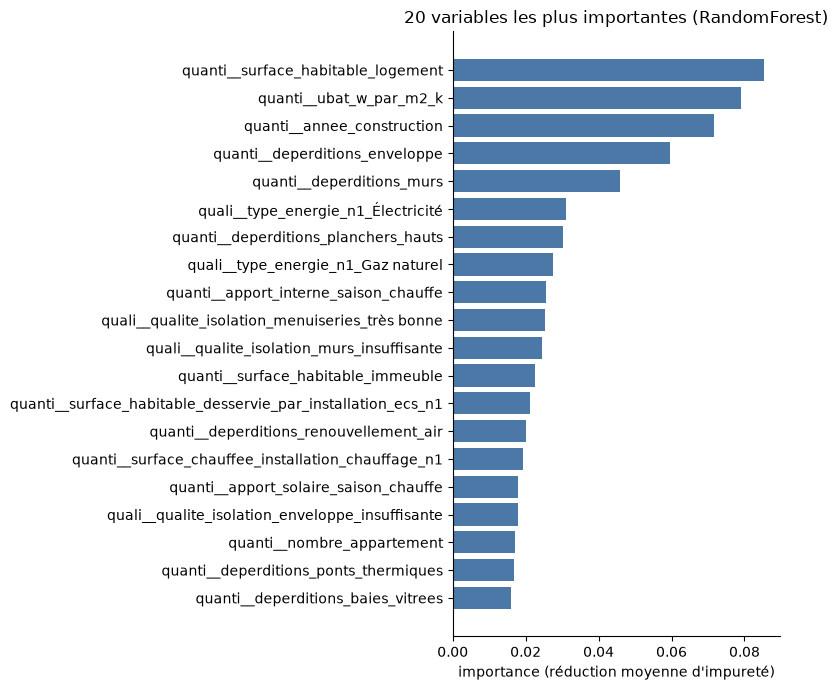

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

best_rf = search_rf2.best_estimator_
y_dpe_pred = best_rf.predict(X_dpe_test)

# matrice de confusion normalisée par ligne : chaque ligne = rappel de la vraie classe
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_dpe_test, y_dpe_pred, normalize="true", values_format=".2f",
                                        cmap="Blues", colorbar=False, ax=ax)
ax.set_title("Matrice de confusion (test)")
plt.show()

ecart = (y_dpe_test.map(ord) - pd.Series(y_dpe_pred, index=y_dpe_test.index).map(ord)).abs()
print(f"prédictions exactes: {(ecart == 0).mean():.3f}")
print(f"prédictions à une classe près: {(ecart <= 1).mean():.3f} <= en gros c'est à quel point on est proche de la bonne classe (genre si on a A, à quel point on est bon ou pas par rapport à B ou C)")



#importances variables
noms_variables = best_rf[:-1].get_feature_names_out()
importances = pd.Series(best_rf.named_steps["model"].feature_importances_, index=noms_variables)
top_importances = importances.sort_values().tail(20)

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top_importances.index, top_importances.values, color="#4C78A8")
ax.set_title("20 variables les plus importantes (RandomForest)")
ax.set_xlabel("importance (réduction moyenne d'impureté)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [46]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.base import clone

# HistGradientBoosting n'accepte pas la matrice creuse du OneHotEncoder : on force une sortie dense
preprocess_dpe_dense = clone(preprocess_dpe).set_params(sparse_threshold=0)

pipe_gb_dpe = Pipeline([
    ("preprocess", preprocess_dpe_dense),
    ("variance", var),
    ("selection", SelectKBest(k=best_k)),
    ("model", HistGradientBoostingClassifier(random_state=42)),
])
cv = cross_validate(pipe_gb_dpe, X_dpe_train, y_dpe_train, cv=3, scoring=["f1_macro", "accuracy"])

# même tableau que la comparaison LogisticRegression / RandomForest, avec le gradient boosting en plus
resultat_gb = {
    "modele": "GradientBoosting",
    "f1_macro": cv["test_f1_macro"].mean(),
    "accuracy": cv["test_accuracy"].mean(),
    "temps_fit (s)": cv["fit_time"].mean(),
}
pd.DataFrame(resultats_dpe + [resultat_gb]).sort_values("f1_macro", ascending=False).set_index("modele").round(3)

,f1_macro,accuracy,temps_fit (s)
modele,,,
GradientBoosting,0.770,0.809,68.748
RandomForest,0.728,0.775,53.207
LogisticRegression,0.599,0.667,42.103


In [ ]:
# recherche des hyperparamètres du GradientBoosting (meilleur modèle de la comparaison)
# 8 combinaisons x 2 plis = 16 fits
param_grid_gb_dpe = {
    "model__learning_rate": [0.05, 0.1],
    "model__max_leaf_nodes": [31, 63],
    "model__class_weight": [None, "balanced"],  # "balanced" pour aider les classes rares (B, F, G)
}
search_gb_dpe = GridSearchCV(pipe_gb_dpe, param_grid_gb_dpe, cv=2, scoring="f1_macro", return_train_score=True)
search_gb_dpe.fit(X_dpe_train, y_dpe_train)

print(search_gb_dpe.best_params_)
print(f"f1_macro train: {search_gb_dpe.cv_results_['mean_train_score'][search_gb_dpe.best_index_]:.3f}")
print(f"f1_macro CV: {search_gb_dpe.best_score_:.3f}")
print(classification_report(y_dpe_test, search_gb_dpe.predict(X_dpe_test)))

pd.DataFrame(search_gb_dpe.cv_results_)[["params", "mean_train_score", "mean_test_score", "mean_fit_time"]].round(3)

In [ ]:
from sklearn.inspection import permutation_importance

best_gb_dpe = search_gb_dpe.best_estimator_

#importances variables
# le gradient boosting n'a pas de feature_importances_ : on mélange chaque variable et on regarde de combien le f1_macro baisse
# (sur un échantillon du test pour que ce soit rapide)
echantillon_dpe = X_dpe_test.sample(5000, random_state=42)
res_gb_dpe = permutation_importance(best_gb_dpe, echantillon_dpe, y_dpe_test.loc[echantillon_dpe.index],
                                    scoring="f1_macro", n_repeats=3, random_state=42, n_jobs=-1)
importances_gb_dpe = pd.Series(res_gb_dpe.importances_mean, index=X_dpe_test.columns)
top_importances_gb = importances_gb_dpe.sort_values().tail(20)

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top_importances_gb.index, top_importances_gb.values, color="#4C78A8")
ax.set_title("20 variables les plus importantes (GradientBoosting)")
ax.set_xlabel("baisse du f1_macro quand la variable est mélangée")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Pour la consommation, on peut tester: linearregression, lasso (mais on a déjà la selection donc jsp), elasticnet, randomforestregressor, gradient mais flemme...

### 1.5.2 Regrsesion

In [24]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

# un apercu des stats sur la variable à prédire
print(y_conso_train.describe().round(1))

count    97164.0
mean       146.6
std         98.7
min          3.1
25%         71.3
50%        121.0
75%        200.8
max        942.0
Name: conso_5_usages_par_m2_ef, dtype: float64


In [33]:
# Petite fonction pour evaluer le modèle sur des données de test après...
def evaluer(nom, y_vrai, y_pred):
    return {"modele": nom,
            "R2": r2_score(y_vrai, y_pred),
            "MAE (kWh/m²/an)": mean_absolute_error(y_vrai, y_pred),
            "RMSE (kWh/m²/an)": root_mean_squared_error(y_vrai, y_pred)}

1. Modèle Baseline: Ce modèle apprend uniquement la médiane de la consommation du train, ignore toutes les variables d’entrée, et prédit toujours cette même valeur. C’est le score à battre : si un vrai modèle ne fait pas mieux, il ne sert à rien.

In [ ]:
# 1- Modele baseline(Tout autre modèle doit faire mieux.)
baseline = DummyRegressor(strategy="median").fit(X_conso_train, y_conso_train)

In [26]:
# On predit ce modèle de base sur les données de test
pd.DataFrame([evaluer("Baseline (médiane)", y_conso_test, baseline.predict(X_conso_test))]).set_index("modele").round(3)

,R2,MAE (kWh/m²/an),RMSE (kWh/m²/an)
modele,,,
Baseline (médiane),-0.068,74.175,100.741


In [ ]:
# 2- Modeles(LinearRegression, Ridge, RandomForest)
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import cross_validate

#Preprocess data
preprocess_conso = ColumnTransformer([
    ("quanti", Pipeline([("imputer", quanti_imputer), ("scaler", scaler)]), quant_cols_dpe),
    ("quali", Pipeline([("imputer", quali_imputer), ("encoder", encoder)]), quali_cols_dpe),
])

# Dictionnaire des trois modèles à comparer
modeles_conso = {
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "RandomForest": RandomForestRegressor(n_estimators=100,  max_features="sqrt", n_jobs=-1, random_state=42),
}
# Liste vide pour recuperer le resutat des modèles
resultats_conso = []
for nom, modele in modeles_conso.items():
    pipe = Pipeline([
    ("preprocess", preprocess_conso),
    ("variance", var),
    ("selection", SelectKBest(score_func=f_regression, k="all")),
    ("model", modele),
    ])

    # une cross_validation pour avoir des resultats fiables avec plusieurs essai
    cv = cross_validate(pipe, X_conso_train, y_conso_train, cv=3, scoring=["r2", "neg_mean_absolute_error"])
    resultats_conso.append({
        "modele": nom,
        "R2": cv["test_r2"].mean(),
        "MAE (kWh/m²/an)": -cv["test_neg_mean_absolute_error"].mean(),
        "temps_fit (s)": cv["fit_time"].mean(),
    })

# liste en tableau en affichant du plus au moins bon
pd.DataFrame(resultats_conso).sort_values("R2", ascending=False).set_index("modele").round(3)


,R2,MAE (kWh/m²/an),temps_fit (s)
modele,,,
RandomForest,0.889,18.194,349.458
LinearRegression,0.336,32.675,14.353
Ridge,0.334,32.636,7.186


- Le RandomForest est nettement meilleur. Il explique environ 89 % de la variation de la consommation, et se trompe en moyenne de 18 kWh/m²/an, contre 74 pour la baseline. C’est un très bon résultat.
- Les modèles linéaires sont faibles (R² 0,33). Les relations entre les variables et la consommation ne sont pas linéaires : le type de chauffage, l’isolation et la surface interagissent. 

In [ ]:
# 3- Modele GradientBoostingRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import OrdinalEncoder
import numpy as np

# colonnes numériques telles quelles (le modèle gère les cases vides) ;
# colonnes de texte -> numéros (valeur jamais vue ou vide -> case vide)
preprocess_gb = ColumnTransformer([
    ("quanti", "passthrough", quant_cols_dpe),
    ("quali", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan, encoded_missing_value=np.nan), quali_cols_dpe),
])

# testons Gradient boosting regressor pour evaluer aussi sa perfomance par rapport à RandomForest
pipe_gb = Pipeline([
    ("preprocess", preprocess_gb),
    ("model", HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1, random_state=42)),
])

cv = cross_validate(pipe_gb, X_conso_train, y_conso_train, cv=3,
                    scoring=["r2", "neg_mean_absolute_error"])
print(f"R2 CV: {cv['test_r2'].mean():.3f}")
print(f"MAE CV: {-cv['test_neg_mean_absolute_error'].mean():.1f} kWh/m²/an")
print(f"temps_fit: {cv['fit_time'].mean():.0f} s")

pipe_gb.fit(X_conso_train, y_conso_train)
pd.DataFrame([evaluer("GradientBoosting (test)", y_conso_test, pipe_gb.predict(X_conso_test))]).set_index("modele").round(3)

R2 CV: 0.945
MAE CV: 13.3 kWh/m²/an
temps_fit: 8 s


,R2,MAE (kWh/m²/an),RMSE (kWh/m²/an)
modele,,,
GradientBoosting (test),0.946,13.099,22.665


- Il est meilleur et 40 fois plus rapide. C’est donc lui qu’on garde.
- Le jeu de test confirme : R² 0,946 et MAE 13,1, quasiment identiques à la validation croisée (0,945 et 13,3). Le modèle ne mémorise pas : il généralise à des logements qu’il n’a jamais vus.
- L’erreur moyenne est de 13 kWh/m²/an, contre 74 pour la baseline. Le RMSE (22,7) est plus grand que la MAE, donc quelques logements sont moins bien prédits, probablement ceux à très forte consommation. Le nuage « prédit contre réel » le montrera.
- Un temps de 8 secondes permet de régler les hyperparamètres rapidement.

In [ ]:
# 4- Testons plusieurs parametres avec GridSearchCV pour selectionner les meilleurs params du modele
from sklearn.model_selection import GridSearchCV

pipe_gb = Pipeline([
    ("preprocess", preprocess_gb),
    ("model", HistGradientBoostingRegressor(max_iter=1000, early_stopping=True,
                                            n_iter_no_change=20, random_state=42)),
])

param_grid_gb = {
    "model__learning_rate": [0.05, 0.1],
    "model__max_leaf_nodes": [31, 63],
    "model__min_samples_leaf": [20, 50],
}
search_gb = GridSearchCV(pipe_gb, param_grid_gb, cv=3, scoring="r2", return_train_score=True)
search_gb.fit(X_conso_train, y_conso_train)

print(search_gb.best_params_)
print(f"R2 train: {search_gb.cv_results_['mean_train_score'][search_gb.best_index_]:.3f}")
print(f"R2 CV: {search_gb.best_score_:.3f}")
y_conso_pred = search_gb.predict(X_conso_test)
print(pd.DataFrame([evaluer("GradientBoosting réglé (test)", y_conso_test, y_conso_pred)]).set_index("modele").round(3))

pd.DataFrame(search_gb.cv_results_)[["params", "mean_train_score", "mean_test_score", "mean_fit_time"]].round(3)

{'model__learning_rate': 0.1, 'model__max_leaf_nodes': 31, 'model__min_samples_leaf': 50}
R2 train: 0.980
R2 CV: 0.952
                                  R2  MAE (kWh/m²/an)  RMSE (kWh/m²/an)
modele                                                                 
GradientBoosting réglé (test)  0.953           11.398            21.092


,params,mean_train_score,mean_test_score,mean_fit_time
0,"{'model__learning_rate': 0.05, 'model__max_lea...",0.975,0.951,11.930
1,"{'model__learning_rate': 0.05, 'model__max_lea...",0.973,0.951,10.790
2,"{'model__learning_rate': 0.05, 'model__max_lea...",0.983,0.952,17.825
3,"{'model__learning_rate': 0.05, 'model__max_lea...",0.981,0.952,22.818
4,"{'model__learning_rate': 0.1, 'model__max_leaf...",0.982,0.952,17.323
5,"{'model__learning_rate': 0.1, 'model__max_leaf...",0.980,0.952,11.047
6,"{'model__learning_rate': 0.1, 'model__max_leaf...",0.986,0.951,11.235
7,"{'model__learning_rate': 0.1, 'model__max_leaf...",0.984,0.951,15.558


                                  R2  MAE (kWh/m²/an)  RMSE (kWh/m²/an)
modele                                                                 
GradientBoosting réglé (test)  0.953           11.398            21.092


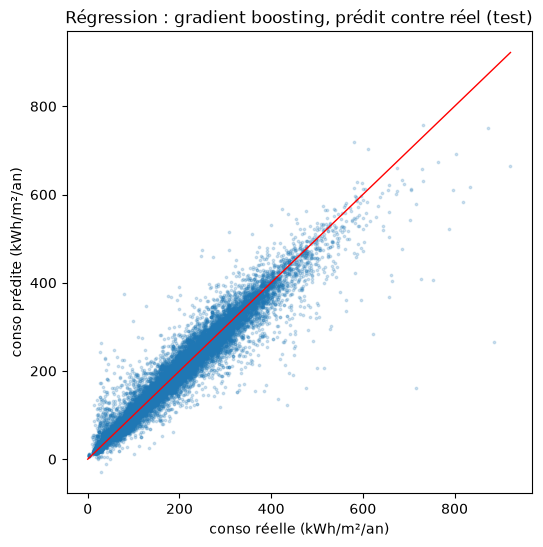

In [35]:
import matplotlib.pyplot as plt

# Meilleur modèle : celui que la grille a retenu, déjà entraîné sur tout le train
meilleur = search_gb.best_estimator_
# (si tu n'as pas lancé la grille : meilleur = pipe_gb.fit(X_conso_train, y_conso_train))

y_conso_pred = meilleur.predict(X_conso_test)
print(pd.DataFrame([evaluer("GradientBoosting réglé (test)", y_conso_test, y_conso_pred)]).set_index("modele").round(3))

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_conso_test, y_conso_pred, s=3, alpha=0.2)
limite = max(y_conso_test.max(), y_conso_pred.max())
ax.plot([0, limite], [0, limite], color="red", lw=1)     # la droite « prédiction parfaite »
ax.set_xlabel("conso réelle (kWh/m²/an)")
ax.set_ylabel("conso prédite (kWh/m²/an)")
ax.set_title("Régression : gradient boosting, prédit contre réel (test)")
plt.show()

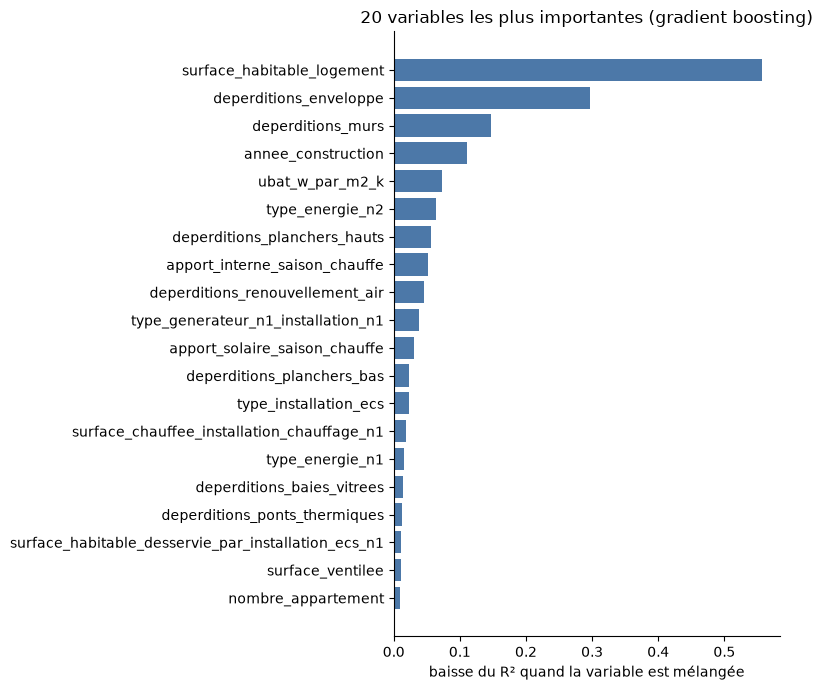

In [ ]:
# 5- Les 20 variables les plus significatifs pour le modele
from sklearn.inspection import permutation_importance

meilleur = search_gb.best_estimator_

# on mélange chaque colonne d'origine et on regarde de combien le R² baisse
# (sur un échantillon du test pour que ce soit rapide)
echantillon = X_conso_test.sample(min(5000, len(X_conso_test)), random_state=42)
res = permutation_importance(meilleur, echantillon, y_conso_test.loc[echantillon.index], scoring="r2", n_repeats=3, random_state=42, n_jobs=-1)

importances_gb = pd.Series(res.importances_mean, index=X_conso_test.columns).sort_values()
top = importances_gb.tail(20)

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top.index, top.values, color="#4C78A8")
ax.set_title("20 variables les plus importantes (gradient boosting)")
ax.set_xlabel("baisse du R² quand la variable est mélangée")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

#### Importance des variables (gradient boosting réglé)

L'importance est mesurée par permutation : on mélange les valeurs d'une colonne sur le jeu de test et on regarde de combien le R² baisse. Plus la baisse est forte, plus le modèle s'appuie sur la variable.

**Ce que montre le graphique**
- `surface_habitable_logement` domine (baisse du R² d'environ 0,56). La cible est une consommation par m², et les petits logements consomment davantage par m² : le modèle utilise aussi la surface pour ramener les déperditions, qui sont des totaux, à une valeur par m².
- Les `deperditions_*` (enveloppe, murs, planchers hauts, renouvellement d'air, planchers bas, baies vitrées, ponts thermiques) pèsent beaucoup, en particulier `deperditions_enveloppe` (environ 0,30) et `deperditions_murs` (environ 0,15).
- Viennent ensuite `annee_construction` (environ 0,11), `ubat_w_par_m2_k`, les apports interne et solaire de la saison de chauffe (`apport_*`), puis l'énergie et le type de générateur de chauffage.

**Limite pour l'application**
Les `deperditions_*`, les `apport_*` et `ubat_w_par_m2_k` sont des résultats intermédiaires du calcul du DPE : le logiciel du diagnostiqueur les calcule à partir de la composition des murs, de l'isolation et des fenêtres. Ce ne sont pas la réponse elle-même (elles n'étaient donc pas dans `fuite_list`), mais elles portent une grande partie de l'information du calcul. Un particulier qui remplirait un formulaire ne peut pas les fournir.

Une partie du R² de 0,95 vient donc de variables qu'on ne connaît qu'après un diagnostic complet. Pour une page de prédiction destinée aux particuliers, il faut un modèle qui n'utilise que des informations accessibles (surface, année de construction, type de bâtiment, énergie et type de chauffage, qualité d'isolation, zone climatique...).

**Suite**
On réentraîne le même modèle, avec les mêmes réglages, en retirant `deperditions_*`, `apport_*` et `ubat_w_par_m2_k`, et on compare les scores sur le jeu de test pour mesurer ce que ces variables apportaient. Point à vérifier avec l'équipe : `ubat_w_par_m2_k` est signalé comme résultat de calcul dans `preprocessing.py`, mais n'est pas retiré dans ce notebook.

In [37]:
# variables issues du calcul du DPE : l'utilisateur de l'application ne peut pas les connaître
calcul_list = [c for c in X_conso_train.columns
               if c.startswith(("deperditions_", "apport_")) or c == "ubat_w_par_m2_k"]
print(len(calcul_list), "variables retirées :", calcul_list)

quant_simple = [c for c in quant_cols_dpe if c not in calcul_list]

preprocess_gb_simple = ColumnTransformer([
    ("quanti", "passthrough", quant_simple),
    ("quali", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan,
                             encoded_missing_value=np.nan), quali_cols_dpe),
])   # les colonnes qui ne sont dans aucune liste sont ignorées

pipe_simple = Pipeline([
    ("preprocess", preprocess_gb_simple),
    ("model", HistGradientBoostingRegressor(learning_rate=0.1, max_leaf_nodes=31, min_samples_leaf=50,
                                            max_iter=1000, early_stopping=True,
                                            n_iter_no_change=20, random_state=42)),
]).fit(X_conso_train, y_conso_train)

y_simple_pred = pipe_simple.predict(X_conso_test)
pd.DataFrame([
    evaluer("GB complet (test)", y_conso_test, search_gb.predict(X_conso_test)),
    evaluer("GB sans variables de calcul (test)", y_conso_test, y_simple_pred),
]).set_index("modele").round(3)

13 variables retirées : ['deperditions_murs', 'deperditions_planchers_bas', 'deperditions_enveloppe', 'apport_solaire_saison_chauffe', 'deperditions_renouvellement_air', 'apport_interne_saison_froide', 'apport_interne_saison_chauffe', 'apport_solaire_saison_froide', 'deperditions_ponts_thermiques', 'deperditions_baies_vitrees', 'ubat_w_par_m2_k', 'deperditions_planchers_hauts', 'deperditions_portes']


,R2,MAE (kWh/m²/an),RMSE (kWh/m²/an)
modele,,,
GB complet (test),0.953,11.398,21.092
GB sans variables de calcul (test),0.836,24.212,39.541


#### Modèle sans les variables issues du calcul du DPE

On retire 13 variables intermédiaires du calcul (`deperditions_*`, `apport_*`, `ubat_w_par_m2_k`) et on réentraîne le même gradient boosting avec les mêmes réglages.

| Modèle | R² (test) | MAE (kWh/m²/an) | RMSE (kWh/m²/an) |
|---|---|---|---|
| Complet | 0,953 | 11,4 | 21,1 |
| Sans variables de calcul | 0,836 | 24,2 | 39,5 |

Ces variables apportent beaucoup : sans elles, l'erreur moyenne double. Le modèle reste néanmoins bien meilleur que la baseline (MAE 74) et que les modèles linéaires. Comme un particulier ne peut pas fournir ces valeurs, c'est le modèle simplifié (R² 0,84) qui représente la performance réaliste de la page de prédiction.

In [38]:
echantillon = X_conso_test.sample(min(5000, len(X_conso_test)), random_state=42)
res_s = permutation_importance(pipe_simple, echantillon, y_conso_test.loc[echantillon.index],
                               scoring="r2", n_repeats=3, random_state=42, n_jobs=-1)
imp_simple = pd.Series(res_s.importances_mean, index=X_conso_test.columns).sort_values(ascending=False)
imp_simple = imp_simple[~imp_simple.index.isin(calcul_list)]   # les variables retirées valent 0
imp_simple.head(25).round(4)

annee_construction                                     0.2535
qualite_isolation_enveloppe                            0.1212
surface_habitable_logement                             0.1140
type_energie_n2                                        0.0825
qualite_isolation_plancher_haut_comble_perdu           0.0751
qualite_isolation_murs                                 0.0720
type_generateur_n1_installation_n1                     0.0393
isolation_toiture                                      0.0220
qualite_isolation_plancher_bas                         0.0214
qualite_isolation_menuiseries                          0.0206
type_energie_n1                                        0.0203
type_installation_ecs                                  0.0163
nombre_niveau_logement                                 0.0155
surface_chauffee_installation_chauffage_n1             0.0147
type_generateur_n1_ecs_n1                              0.0115
inertie_lourde                                         0.0112
surface_

#### Conclusion de la régression

- Modèle retenu : gradient boosting (R² 0,95, MAE 11 kWh/m²/an).
- Ce score repose sur des variables calculées par le diagnostiqueur. Sans elles : R² 0,84, MAE 24.

Variables à supprimer (inconnues d'un particulier) :
- `deperditions_murs`, `deperditions_planchers_bas`, `deperditions_planchers_hauts`, `deperditions_enveloppe`, `deperditions_renouvellement_air`, `deperditions_ponts_thermiques`, `deperditions_baies_vitrees`, `deperditions_portes`
- `apport_solaire_saison_chauffe`, `apport_solaire_saison_froide`, `apport_interne_saison_chauffe`, `apport_interne_saison_froide`
- `ubat_w_par_m2_k`

# Test Formulaire

In [37]:
# import ordinal encoder
from sklearn.preprocessing import OrdinalEncoder
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import cross_validate
# r_2_score
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, root_mean_squared_error

In [38]:
# variables qu'un particulier peut raisonnablement renseigner dans un formulaire
base_formulaire = [
    "surface_habitable_logement", "annee_construction", "type_batiment",
    "zone_climatique", "classe_altitude",
    "nombre_niveau_logement", "numero_etage_appartement",
    "type_energie_n1", "type_energie_n2", "type_generateur_n1_installation_n1",
    "type_emetteur_installation_chauffage_n1",
    "type_installation_ecs", "type_generateur_n1_ecs_n1", "type_ventilation",
]
# qualité d'isolation : dans le DPE, c'est un résultat de calcul ; un particulier ne pourrait
# donner qu'une estimation personnelle (on mesure ce que ça apporte)
isolation_percue = [
    "qualite_isolation_enveloppe", "qualite_isolation_murs",
    "qualite_isolation_plancher_haut_comble_perdu", "qualite_isolation_plancher_bas",
    "qualite_isolation_menuiseries", "isolation_toiture",
]

def modele_sur(colonnes, nom):
    """Entraîne le gradient boosting réglé sur ces colonnes seulement ; renvoie les scores test."""
    colonnes = [c for c in colonnes if c in X_conso_train.columns]
    quanti = [c for c in colonnes if c in quant_cols_dpe]
    quali = [c for c in colonnes if c in quali_cols_dpe]
    pipe = Pipeline([
        ("preprocess", ColumnTransformer([
            ("quanti", "passthrough", quanti),
            ("quali", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan,
                                     encoded_missing_value=np.nan), quali)])),
        ("model", HistGradientBoostingRegressor(learning_rate=0.1, max_leaf_nodes=31,
                                                min_samples_leaf=50, max_iter=1000,
                                                early_stopping=True, n_iter_no_change=20,
                                                random_state=42)),
    ]).fit(X_conso_train, y_conso_train)
    resultat = evaluer(nom, y_conso_test, pipe.predict(X_conso_test))
    resultat["nb_variables"] = len(colonnes)
    return resultat

pd.DataFrame([
    modele_sur(base_formulaire + isolation_percue, "Formulaire avec isolation estimée"),
    modele_sur(base_formulaire, "Formulaire sans isolation"),
]).set_index("modele").round(3)

,R2,MAE (kWh/m²/an),RMSE (kWh/m²/an),nb_variables
modele,,,,
Formulaire avec isolation estimée,0.817,25.984,41.737,20
Formulaire sans isolation,0.718,32.675,51.789,14


#### Modèle pour la page de prédiction (variables accessibles à un particulier)

On ne garde que les variables qu'un particulier peut renseigner : surface, année de construction, type de bâtiment, zone climatique et altitude (déduites de la commune), niveaux et étage, énergies et type de chauffage, émetteurs, eau chaude, ventilation (14 variables), avec ou sans une estimation de la qualité d'isolation (6 variables supplémentaires).

| Modèle (gradient boosting réglé) | Variables | R² (test) | MAE (kWh/m²/an) | RMSE (kWh/m²/an) |
|---|---|---|---|---|
| Complet | 64 | 0,953 | 11,4 | 21,1 |
| Sans variables de calcul du DPE | 51 | 0,836 | 24,2 | 39,5 |
| Formulaire avec isolation estimée | 20 | 0,817 | 26,0 | 41,7 |
| Formulaire sans isolation | 14 | 0,718 | 32,7 | 51,8 |

Passer de 51 à 20 variables ne coûte que 0,02 de R² : la plupart des variables techniques n'apportent presque rien une fois les variables de calcul retirées. L'estimation de l'isolation, elle, compte beaucoup (+0,10 de R²). Elle reste une estimation de l'utilisateur, moins fiable que la valeur calculée par un diagnostiqueur : la performance réelle du formulaire sera un peu inférieure à celle mesurée ici.

In [44]:
# nombre de classes de chaque variable catégorielle du formulaire
variables_formulaire = base_formulaire + isolation_percue
pd.DataFrame(
    {"nb_classes": [X_conso_train[c].nunique() for c in variables_formulaire if c in quali_cols_dpe]},
    index=[c for c in variables_formulaire if c in quali_cols_dpe],
)

,nb_classes
type_batiment,2
zone_climatique,9
classe_altitude,4
type_energie_n1,13
type_energie_n2,13
type_generateur_n1_installation_n1,133
type_emetteur_installation_chauffage_n1,43
type_installation_ecs,3
type_generateur_n1_ecs_n1,88
type_ventilation,39


In [45]:
# variables du formulaire avec plus de 10 classes : nombre de logements par classe
for c in variables_formulaire:
    if c in quali_cols_dpe and X_conso_train[c].nunique() > 10:
        print(f"\n{c} ({X_conso_train[c].nunique()} classes)")
        print(X_conso_train[c].value_counts().to_string())


type_energie_n1 (13 classes)
type_energie_n1
Gaz naturel                                                     53349
Électricité                                                     35130
Réseau de Chauffage urbain                                       4209
Fioul domestique                                                 1652
Bois – Bûches                                                    1089
Bois – Granulés (pellets) ou briquettes                          1071
Bois – Plaquettes forestières                                     241
Charbon                                                           202
GPL                                                               164
Électricité d'origine renouvelable utilisée dans le bâtiment       34
Propane                                                            17
Bois – Plaquettes d’industrie                                       5
Butane                                                              1

type_energie_n2 (13 classes)
type_energie_n